# Profile: UFGS (Unified Facilities Guide Specifications)

What is in the specification PDFs, what is missing, how the values are spread, and what a
section looks like. The findings at the end feed Module A (spec RAG): parsing, chunk size and
whether OCR is needed.

| | |
|---|---|
| **What** | US military construction specifications (USACE / NAVFAC / AFCEC), one PDF per section |
| **Source** | https://www.wbdg.org/dod/ufgs (section list: https://www.wbdg.org/api/sitemap/documents.xml) |
| **Version** | Current version of each **active** section on the download day. Publish dates in the files: 2006-04-01 to 2026-08-01 |
| **License** | No license, copyright or distribution statement was found in the 271 PDFs or the WBDG API record (checked 2026-10-16). Background, not a legal conclusion: page 1 of each PDF names USACE / NAVFAC / AFCEC (US government agencies), and 17 U.S.C. § 105(a) says copyright protection "is not available for any work of the United States Government"; whether every section was written that way is not stated in the files. Standards cited in the text (e.g. ASTM) are **not** included |
| **Citation** | Unified Facilities Guide Specifications (UFGS), Whole Building Design Guide, https://www.wbdg.org/dod/ufgs |

Copied from [`data/DATA_CATALOG.md`](../data/DATA_CATALOG.md). Spec:
[`specs/2026-10-16-profiling-notebooks/`](../specs/2026-10-16-profiling-notebooks/spec.md).

Run headless (inside the container, about one minute):
`uv run --with jupyterlab jupyter nbconvert --to notebook --execute --inplace notebooks/00_profile_ufgs.ipynb`

PDFs are opened one at a time with PyMuPDF and closed again; nothing is changed or written.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from src.common import config
from src.datasets.profiling import first_lines, missing_table, ufgs_pdf_stats

plt.rcParams.update({"figure.dpi": 72, "figure.figsize": (10, 3)})
pd.set_option("display.max_columns", 30, "display.width", 120)

UFGS = config.RAW_DIR / "ufgs"
manifest = pd.DataFrame(
    json.loads((UFGS / "manifest.json").read_text(encoding="utf-8"))["sections"]
)
stats = ufgs_pdf_stats(UFGS)  # opens every PDF once: about one minute
stats["local_path"] = stats["division"] + "/" + stats["file"]
stats["chars_per_page"] = stats["text_chars"] / stats["pages"]
active = manifest[manifest["api_status"] == "ACTIVE"]
pdfs = stats.merge(active[["local_path", "section_id", "title", "publish_date"]], how="left")
pdfs["publish_year"] = pd.to_datetime(pdfs["publish_date"]).dt.year

## 1. Counts

In [2]:
print(f"manifest: {len(manifest)} sections, {manifest['api_status'].value_counts().to_dict()}")
print(f"PDFs on disk: {len(stats)}, {stats['bytes'].sum():,} bytes")
print(f"pages: {stats['pages'].sum():,}, text characters: {stats['text_chars'].sum():,}")
per_division = (
    pd.DataFrame(
        {
            "active_in_manifest": active.groupby("division").size(),
            "pdfs_on_disk": stats.groupby("division").size(),
            "pages": stats.groupby("division")["pages"].sum(),
        }
    )
    .fillna(0)
    .astype(int)
)
per_division

manifest: 705 sections, {'RETIRED_SUPERSEDED': 434, 'ACTIVE': 271}
PDFs on disk: 271, 37,587,638 bytes
pages: 10,337, text characters: 24,521,049


,active_in_manifest,pdfs_on_disk,pages
division,,,
01,33,33,1017
03,23,23,882
05,17,17,320
22,11,11,560
23,52,52,2411
26,45,45,1900
33,59,59,2004
40,4,4,248
41,8,8,387


## 2. Missing values

Sections that should be on disk but are not, PDFs that the manifest does not know, pages without
a text layer (they would need OCR), and gaps in the manifest fields we use.

In [3]:
on_disk = set(stats["local_path"])
not_on_disk = sorted(set(active["local_path"]) - on_disk)
not_in_manifest = sorted(on_disk - set(active["local_path"]))
print(f"active sections without a PDF on disk: {len(not_on_disk)} {not_on_disk[:10]}")
print(
    f"PDFs on disk not in the manifest (as active): {len(not_in_manifest)} {not_in_manifest[:10]}"
)
retired = manifest[manifest["api_status"] != "ACTIVE"]
retired_on_disk = int(sum((UFGS / p).exists() for p in retired["local_path"]))
print(f"retired sections in the manifest: {len(retired)}, of them on disk: {retired_on_disk}")
print(
    f"pages without text: {stats['empty_pages'].sum()} "
    f"in {(stats['empty_pages'] > 0).sum()} of {len(stats)} PDFs"
)
gaps = missing_table(pdfs[["section_id", "title", "publish_date", "pages", "text_chars"]])
print(gaps.to_string(index=False))

active sections without a PDF on disk: 0 []
PDFs on disk not in the manifest (as active): 0 []


retired sections in the manifest: 434, of them on disk: 0
pages without text: 0 in 0 of 271 PDFs
      column  missing  missing_pct
  section_id        0          0.0
       title        0          0.0
publish_date        0          0.0
       pages        0          0.0
  text_chars        0          0.0


## 3. Distributions

Length of a section (pages), text per page (a first hint for chunk size), publish year and file
size.

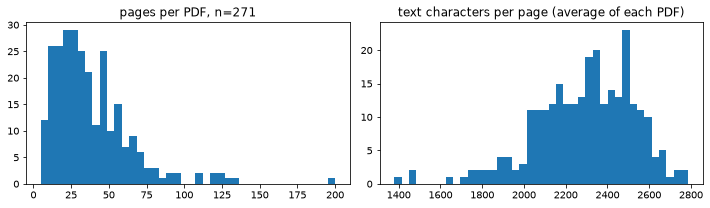

longest section: UFGS 23 52 33.01 Steam Heating Plant Watertube Coal/Oil or Coal (200 pages)


,bytes,pages,text_chars,chars_per_page
count,271.0,271.0,271.0,271.0
mean,138700.0,38.0,90484.0,2292.0
std,144927.0,26.0,66743.0,236.0
min,18351.0,5.0,10393.0,1379.0
25%,64213.0,20.0,42262.0,2146.0
50%,106008.0,32.0,71491.0,2320.0
75%,159240.0,48.0,118568.0,2476.0
max,1491991.0,200.0,490644.0,2788.0


In [4]:
fig, axes = plt.subplots(1, 2)
axes[0].hist(stats["pages"], bins=40)
axes[0].set_title(f"pages per PDF, n={len(stats)}")
axes[1].hist(stats["chars_per_page"], bins=40)
axes[1].set_title("text characters per page (average of each PDF)")
plt.tight_layout()
plt.show()
longest = pdfs.loc[pdfs["pages"].idxmax()]
print(f"longest section: {longest['title']} ({longest['pages']} pages)")
stats[["bytes", "pages", "text_chars", "chars_per_page"]].describe().round(0)

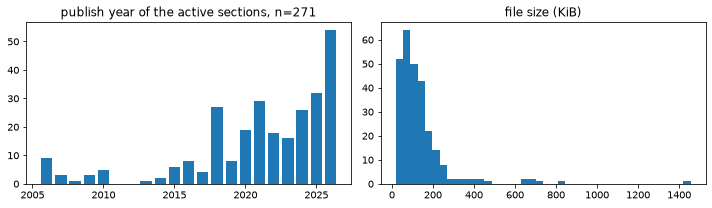

publish years: 2006-2026; published 2020 or later: 194 of 271


In [5]:
years = pdfs["publish_year"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2)
axes[0].bar(years.index, years.to_numpy())
axes[0].set_title(f"publish year of the active sections, n={years.sum()}")
axes[1].hist(stats["bytes"] / 1024, bins=40)
axes[1].set_title("file size (KiB)")
plt.tight_layout()
plt.show()
recent = int((pdfs["publish_year"] >= 2020).sum())
print(
    f"publish years: {pdfs['publish_year'].min()}-{pdfs['publish_year'].max()}; "
    f"published 2020 or later: {recent} of {len(pdfs)}"
)

## 4. Sample records

Title and the first lines of page 1 of three sections (one each from divisions 01, 03 and 26).
Source: UFGS, wbdg.org (see the header).

In [6]:
for division in ["01", "03", "26"]:
    row = pdfs[pdfs["division"] == division].iloc[0]
    print(f"--- {row['title']} ({row['pages']} pages, published {row['publish_date'][:10]})")
    for line in first_lines(UFGS / row["local_path"], 8):
        print("   ", line)

--- UFGS 01 11 00 Summary of Work (8 pages, published 2026-05-01)
    **************************************************************************
    USACE / NAVFAC / AFCEC
    UFGS-01 11 00 (February 2024)
    Change 2 - 05/26
    ------------------------------------
    Preparing Activity:  NAVFAC
    Superseding
    UFGS-01 11 00 (August 2015)
--- UFGS 03 01 00 Rehabilitation of Concrete (51 pages, published 2018-02-01)


    **************************************************************************
    USACE / NAVFAC / AFCEC
    UFGS-03 01 00 (February 2018)
    ------------------------------------
    Preparing Activity:  USACE
    Superseding
    UFGS-03 01 30.71 (April 2006)
    UFGS-03 01 30 (November 2009)
--- UFGS 26 05 13 Medium-Voltage Cables (28 pages, published 2025-08-01)
    **************************************************************************
    USACE / NAVFAC / AFCEC
    UFGS-26 05 13 (August 2025)
    ------------------------------------
    Preparing Activity:  USACE
    Superseding
    UFGS-26 05 13.00 10 (May 2023)
    UNIFIED FACILITIES GUIDE SPECIFICATIONS


## 5. Findings

Every number below is computed from the tables above in this run.

In [7]:
findings = [
    f"{len(stats)} PDFs on disk = {len(active)} active sections in the manifest; "
    f"{len(not_on_disk)} missing and {len(not_in_manifest)} unknown files. "
    f"{len(retired)} retired sections are listed in the manifest; {retired_on_disk} are on disk.",
    f"{stats['empty_pages'].sum()} of {stats['pages'].sum():,} pages have no text layer: "
    + (
        "every page has text, so Module A needs no OCR for UFGS."
        if stats["empty_pages"].sum() == 0
        else "those pages need OCR or are blank (check them in Module A)."
    ),
    f"A section is {stats['pages'].median():.0f} pages long at the median "
    f"(range {stats['pages'].min()}-{stats['pages'].max()}; longest: {longest['title']}). "
    "Whole sections are far too long for one chunk: split by PART / article.",
    f"The median PDF averages about {stats['chars_per_page'].median():,.0f} characters per "
    "page: a first reference for the chunk size in Module A.",
    f"Publish years run {pdfs['publish_year'].min()}-{pdfs['publish_year'].max()}; "
    f"{recent} of {len(pdfs)} sections were published in 2020 or later. "
    "Answers should cite the publish date of the section they use.",
]
for i, text in enumerate(findings, 1):
    print(f"{i}. {text}")

1. 271 PDFs on disk = 271 active sections in the manifest; 0 missing and 0 unknown files. 434 retired sections are listed in the manifest; 0 are on disk.
2. 0 of 10,337 pages have no text layer: every page has text, so Module A needs no OCR for UFGS.
3. A section is 32 pages long at the median (range 5-200; longest: UFGS 23 52 33.01 Steam Heating Plant Watertube Coal/Oil or Coal). Whole sections are far too long for one chunk: split by PART / article.
4. The median PDF averages about 2,320 characters per page: a first reference for the chunk size in Module A.
5. Publish years run 2006-2026; 194 of 271 sections were published in 2020 or later. Answers should cite the publish date of the section they use.
